In [27]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("energy_firms.csv")

df["group"] = df["treated"].map({0: "Untreated", 1: "Treated"})
print(df.dtypes)

firm_id                 str
sector                  str
treated               int64
month                 int64
adjust_month          int64
labor_adjustable      int64
output              float64
labor               float64
electricity         float64
output_price        float64
wage                float64
energy_price        float64
group                   str
dtype: object


In [ ]:
# Check 1: missing values
print("Missing values:", df.isna().sum().sum())


Missing values: 0


In [21]:
# Table 1: number of manufacturing plants per sector

firms = df.drop_duplicates("firm_id")[["firm_id", "sector", "group"]]

table1 = pd.crosstab(df["sector"], df["group"], values=df["firm_id"],
                     aggfunc="nunique", margins=True, margins_name="Total")
print("Table 1: number of manufacturing plants per sector and group")
print(table1)

Table 1: number of manufacturing plants per sector and group
group      Treated  Untreated  Total
sector                              
Chemicals      120        120    240
Textiles       120        120    240
Total          240        240    480


In [ ]:
# Table 2: comparing mean between treated and untreated
def compare_means(data, variables):
    table = data.groupby("group")[variables].mean().T[["Untreated", "Treated"]]
    table["Difference (T - U)"] = table["Treated"] - table["Untreated"]
    return table.round(2)

table1 = compare_means(df, ["output", "labor", "electricity"])
firms = df.drop_duplicates("firm_id")   # prices are fixed per firm
table2 = compare_means(firms, ["output_price", "wage", "energy_price"])
print(table1, "\n")
print(table2)

group        Untreated  Treated  Difference (T - U)
output           76.54    88.68               12.14
labor           161.92   212.27               50.34
electricity    4110.24  4257.03              146.80 

group         Untreated   Treated  Difference (T - U)
output_price   22714.28  23341.82              627.55
wage            1415.70   1404.89              -10.81
energy_price     163.69    162.97               -0.71


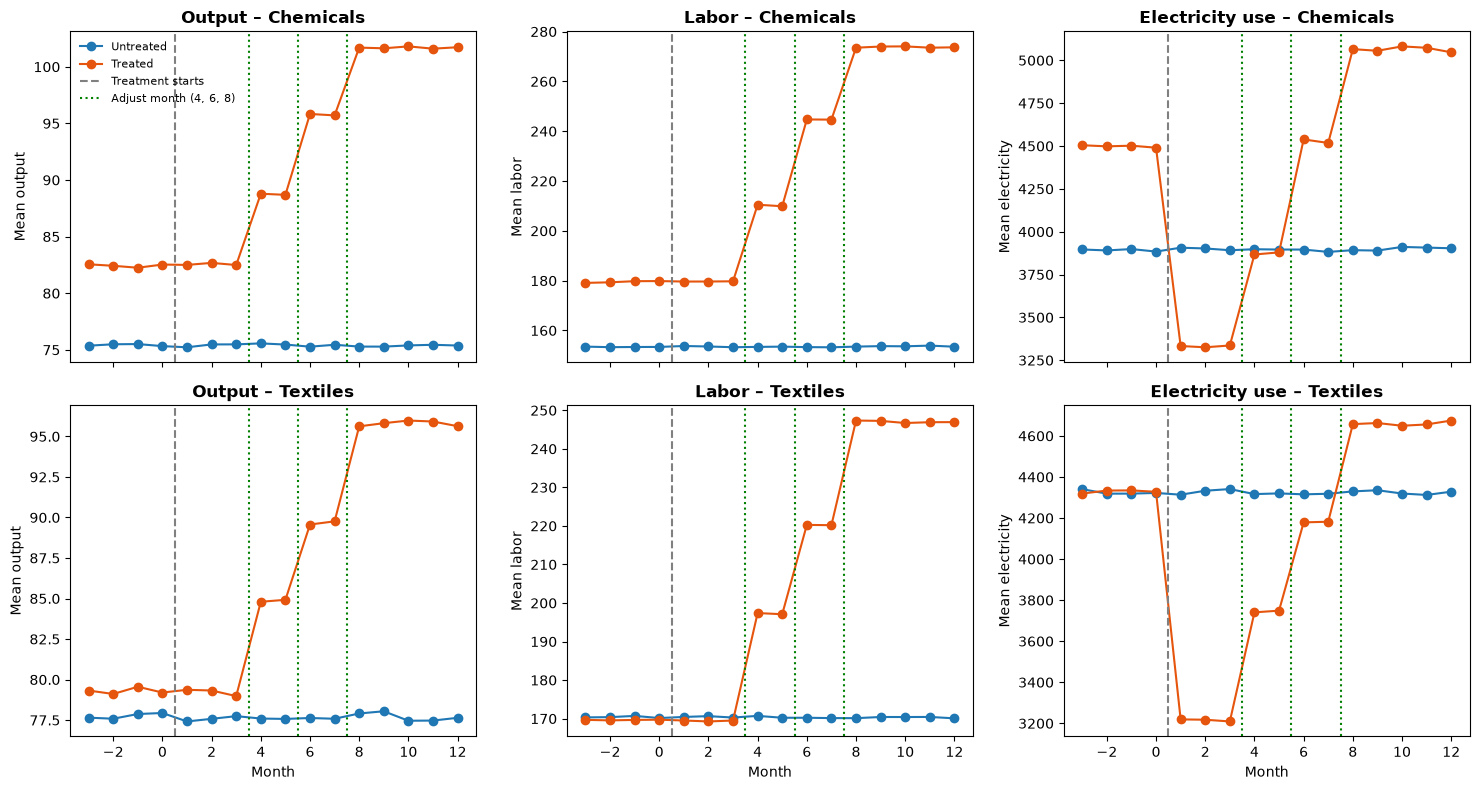

In [32]:
variables = ["output", "labor", "electricity"]
means = df.groupby(["sector", "month", "treated"])[variables].mean().unstack("treated")

titles = ["Output", "Labor", "Electricity use"]
groups = {0: ("Untreated", "#1F77B4"), 1: ("Treated", "#E6550D")}
sectors = sorted(df["sector"].unique())
adjust_months = sorted(df["adjust_month"].unique())   # 4, 6, 8

fig, axes = plt.subplots(len(sectors), 3, figsize=(15, 8), sharex=True)
for row, sector in zip(axes, sectors):
    m = means.loc[sector]
    for ax, var, title in zip(row, variables, titles):
        for g, (label, color) in groups.items():
            ax.plot(m.index, m[(var, g)], marker="o", color=color, label=label)
        ax.axvline(0.5, linestyle="--", color="grey", label="Treatment starts")
        for i, am in enumerate(adjust_months):
            ax.axvline(am - 0.5, linestyle=":", color="green",
                       label="Adjust month (4, 6, 8)" if i == 0 else None)
        ax.set_title(f"{title} – {sector}", fontweight="bold")
        ax.set_ylabel(f"Mean {var}")
for ax in axes[-1]:
    ax.set_xlabel("Month")
axes[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**2 What does the time pattern tell you?**\
Look more closely at the evolution of electricity use. Does a single average for the period after consulting give an adequate account? Identify the features of the time path that would matter to a policymaker, and decide how to present them clearly.

Compare your conclusions across treated and control plants and consider whether the average hides differ-
ences across firms. State the main empirical pattern that your subsequent analysis needs to explain. Keep a description of that pattern separate from an explanation of why it occurs.

**Answer:**
No, a single average for the post-consulting period does not capture the pattern. For the treated group, electricity use falls abruptly right after the consulting begins, and after about three months it rises suddenly to a level higher than before treatment. By following the changes over time, we can also see that output, labor and electricity all increase in the same way from the fourth month onwards. Meanwhile, the untreated group remains unchanged throughout the period.